# DATA 620 — Week Six: Assignment Data Sets

**Andre Thomson**

## Approach

I used the Davis Southern Women dataset from NetworkX. It shows 18 women, 14 social events, and which women attended each event.

I wanted to compare which women showed up at the same events and which events had people in common. I started with the original two-mode network, then made a women-only graph and an events-only graph. The line weights show how much attendance overlap there was.

The colors help me tell the two sides apart. Blue represents the women and orange represents the events.

## 1. Packages

I used NetworkX for the networks, pandas for the tables, and Matplotlib for the graphs.

In [1]:
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
from networkx.algorithms import bipartite

pd.set_option("display.max_rows", 25)
pd.set_option("display.max_columns", 20)

## 2. Load the data

I used the Davis dataset that comes with NetworkX, rather than entering the attendance information myself.

In [2]:
G = nx.davis_southern_women_graph()
women = sorted(G.graph["top"])
events = sorted(G.graph["bottom"], key=lambda x: int(x[1:]))

print("Women:", len(women))
print("Events:", len(events))
print("Attendance links:", G.number_of_edges())
print("Bipartite:", bipartite.is_bipartite(G))

assert len(women) == 18 and len(events) == 14
assert G.number_of_edges() == 89
assert bipartite.is_bipartite(G)
assert set(women).isdisjoint(events)
assert set(G.nodes()) == set(women) | set(events)

Women: 18
Events: 14
Attendance links: 89
Bipartite: True


## 3. Original network

The blue nodes are women and the orange nodes are events. A line means a woman attended an event. Bigger nodes have more attendance links.

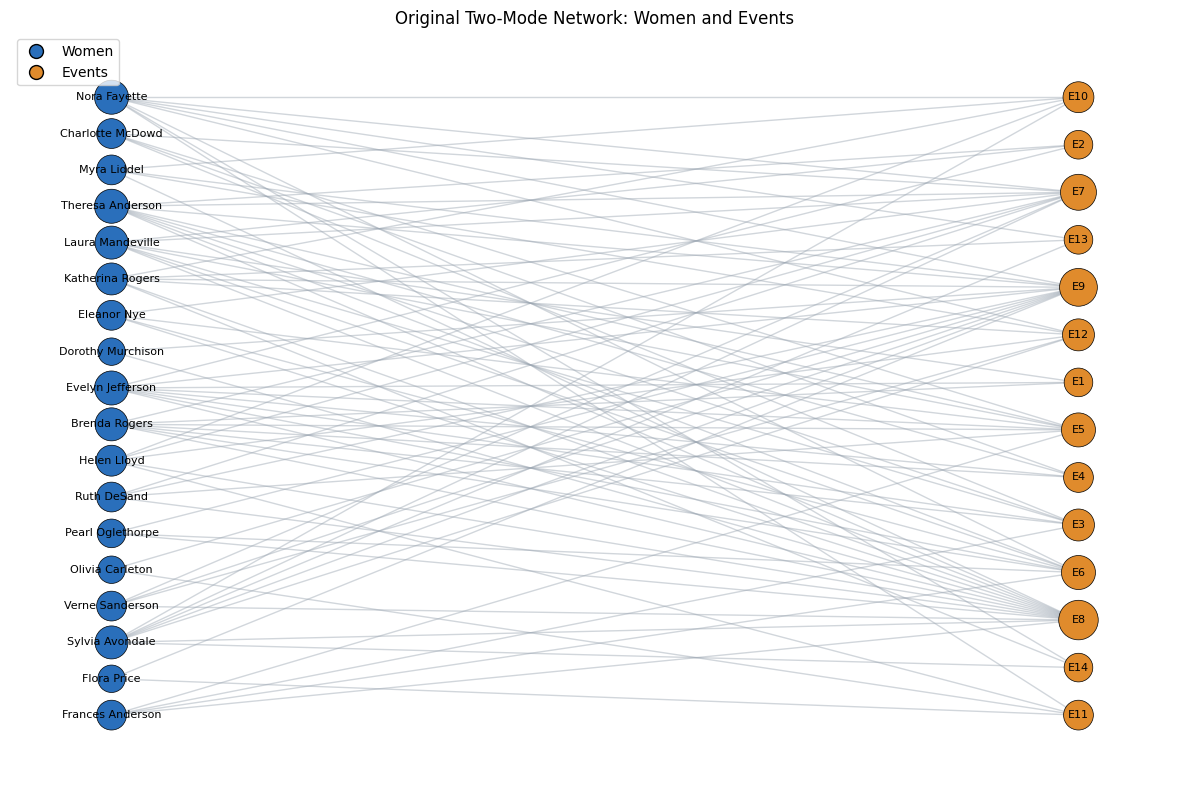

In [3]:
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(12, 8))
pos_b = nx.bipartite_layout(G, women, align="vertical", scale=1.2, aspect_ratio=1.6)

women_sizes = [320 + 35 * G.degree(w) for w in women]
event_sizes = [320 + 35 * G.degree(e) for e in events]

nx.draw_networkx_edges(G, pos_b, edge_color="#9aa5b1", alpha=0.45, width=1.0, ax=ax)
nx.draw_networkx_nodes(G, pos_b, nodelist=women, node_color="#2a6fbb", node_size=women_sizes, edgecolors="black", linewidths=0.5, ax=ax)
nx.draw_networkx_nodes(G, pos_b, nodelist=events, node_color="#e08b2c", node_size=event_sizes, edgecolors="black", linewidths=0.5, ax=ax)
nx.draw_networkx_labels(G, pos_b, font_size=8, ax=ax)

legend_items = [
    Line2D([0], [0], marker="o", color="w", label="Women", markerfacecolor="#2a6fbb", markeredgecolor="black", markersize=10),
    Line2D([0], [0], marker="o", color="w", label="Events", markerfacecolor="#e08b2c", markeredgecolor="black", markersize=10),
]
ax.legend(handles=legend_items, loc="upper left", frameon=True)
ax.set_title("Original Two-Mode Network: Women and Events")
ax.axis("off")
fig.tight_layout()
plt.show()

## 4. Attendance table

A `1` means the woman attended that event. A `0` means the dataset has no attendance link for her at that event.

In [4]:
attendance = pd.DataFrame(
    [[int(G.has_edge(w, event)) for event in events] for w in women],
    index=women, columns=events
)
assert attendance.to_numpy().sum() == 89
attendance

,E1,E2,E3,E4,E5,E6,E7,E8,E9,E10,E11,E12,E13,E14
Brenda Rogers,1,0,1,1,1,1,1,1,0,0,0,0,0,0
Charlotte McDowd,0,0,1,1,1,0,1,0,0,0,0,0,0,0
Dorothy Murchison,0,0,0,0,0,0,0,1,1,0,0,0,0,0
Eleanor Nye,0,0,0,0,1,1,1,1,0,0,0,0,0,0
Evelyn Jefferson,1,1,1,1,1,1,0,1,1,0,0,0,0,0
Flora Price,0,0,0,0,0,0,0,0,1,0,1,0,0,0
Frances Anderson,0,0,1,0,1,1,0,1,0,0,0,0,0,0
Helen Lloyd,0,0,0,0,0,0,1,1,0,1,1,1,0,0
Katherina Rogers,0,0,0,0,0,0,0,1,1,1,0,1,1,1
Laura Mandeville,1,1,1,0,1,1,1,1,0,0,0,0,0,0


### Attendance heatmap

This shows the same attendance data as a chart. It helps me spot women who attended some of the same events.

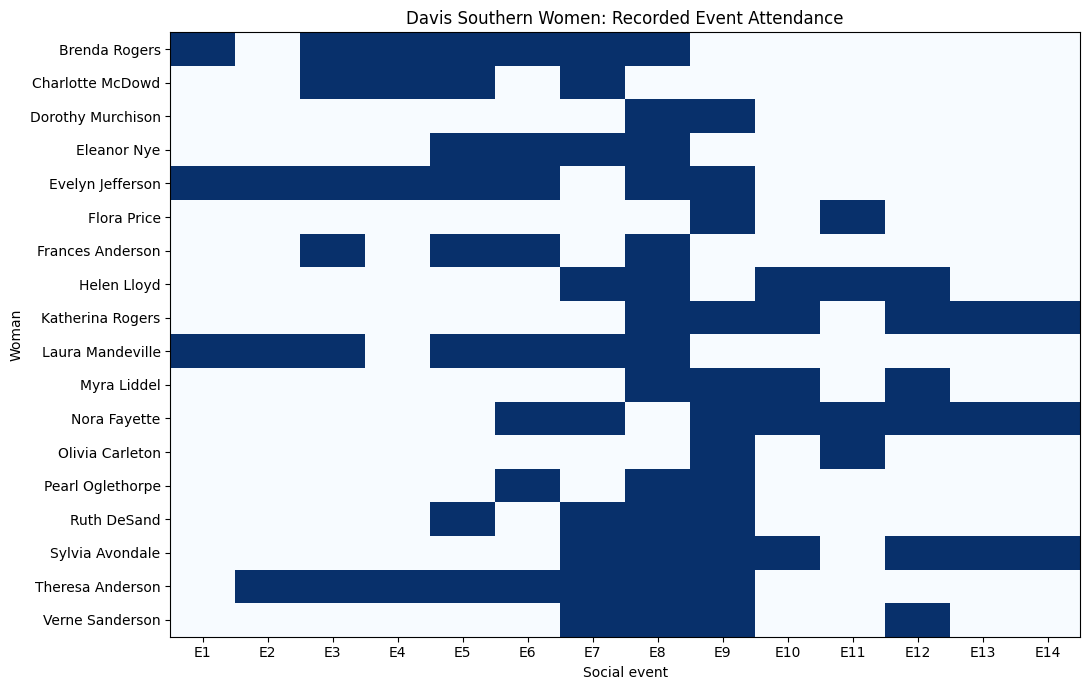

In [5]:
fig, ax = plt.subplots(figsize=(11, 7))
ax.imshow(attendance.to_numpy(), aspect="auto", cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(events)), events)
ax.set_yticks(range(len(women)), women)
ax.set_title("Davis Southern Women: Recorded Event Attendance")
ax.set_xlabel("Social event")
ax.set_ylabel("Woman")
fig.tight_layout()
plt.show()

## 5. Attendance by woman

I counted how many events each woman attended.

In [6]:
women_attendance = pd.DataFrame({
    "woman": women,
    "events_attended": [G.degree(w) for w in women]
}).sort_values(["events_attended", "woman"], ascending=[False, True])
women_attendance

,woman,events_attended
4,Evelyn Jefferson,8
11,Nora Fayette,8
16,Theresa Anderson,8
0,Brenda Rogers,7
9,Laura Mandeville,7
15,Sylvia Avondale,7
8,Katherina Rogers,6
7,Helen Lloyd,5
1,Charlotte McDowd,4
3,Eleanor Nye,4


## 6. Attendance by event

I counted how many women attended each event.

In [7]:
event_attendance = pd.DataFrame({
    "event": events,
    "women_attending": [G.degree(e) for e in events]
}).sort_values(["women_attending", "event"], ascending=[False, True])
event_attendance

,event,women_attending
7,E8,14
8,E9,12
6,E7,10
4,E5,8
5,E6,8
11,E12,6
2,E3,6
9,E10,5
10,E11,4
3,E4,4


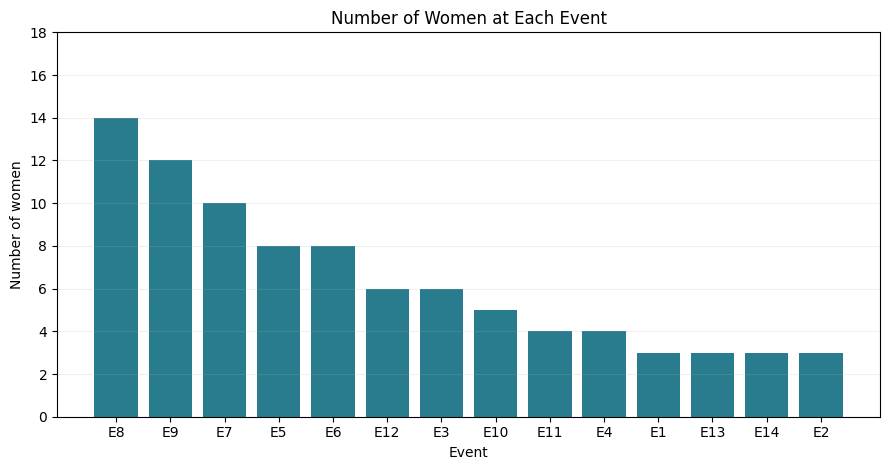

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.bar(event_attendance["event"], event_attendance["women_attending"], color="#287c8e")
ax.set_title("Number of Women at Each Event")
ax.set_xlabel("Event")
ax.set_ylabel("Number of women")
ax.set_ylim(0, 18)
ax.grid(axis="y", alpha=.18)
fig.tight_layout()
plt.show()

## 7. Connections between the women

For this graph, I linked two women when they attended at least one event together. The weight tells me how many events they shared. It does not tell me whether they were friends.

An event with many women can produce several links in this projected graph, so I also looked at how many events each pair shared.

In [9]:
# Create women-to-women links from shared events; weight counts the shared events.
women_graph = bipartite.weighted_projected_graph(G, women)
print("Women in projection:", women_graph.number_of_nodes())
print("Pairs sharing at least one event:", women_graph.number_of_edges())

women_links = sorted(
    [(a, b, d["weight"]) for a, b, d in women_graph.edges(data=True)],
    key=lambda x: (-x[2], x[0], x[1])
)
pd.DataFrame(women_links[:12], columns=["woman_1", "woman_2", "shared_events"])

Women in projection: 18
Pairs sharing at least one event: 139


,woman_1,woman_2,shared_events
0,Evelyn Jefferson,Theresa Anderson,7
1,Brenda Rogers,Evelyn Jefferson,6
2,Brenda Rogers,Laura Mandeville,6
3,Brenda Rogers,Theresa Anderson,6
4,Evelyn Jefferson,Laura Mandeville,6
5,Katherina Rogers,Sylvia Avondale,6
6,Laura Mandeville,Theresa Anderson,6
7,Nora Fayette,Sylvia Avondale,6
8,Katherina Rogers,Nora Fayette,5
9,Brenda Rogers,Charlotte McDowd,4


### Women with the most shared attendance

`other_women` counts how many different women each woman shared an event with. `shared_event_total` adds up the number of shared events across her connections.

In [10]:
women_summary = pd.DataFrame({
    "woman": women,
    "events_attended": [G.degree(w) for w in women],
    "other_women": [women_graph.degree(w) for w in women],
    "shared_event_total": [women_graph.degree(w, weight="weight") for w in women],
}).sort_values(["shared_event_total", "woman"], ascending=[False, True])
women_summary

,woman,events_attended,other_women,shared_event_total
16,Theresa Anderson,8,17,57
4,Evelyn Jefferson,8,17,50
0,Brenda Rogers,7,15,46
15,Sylvia Avondale,7,17,46
9,Laura Mandeville,7,15,45
11,Nora Fayette,8,17,43
14,Ruth DeSand,4,17,40
17,Verne Sanderson,4,17,38
8,Katherina Rogers,6,16,37
3,Eleanor Nye,4,15,36


### Women network graph

Darker blue means a woman attended more events. Thicker lines mean two women attended more events together.

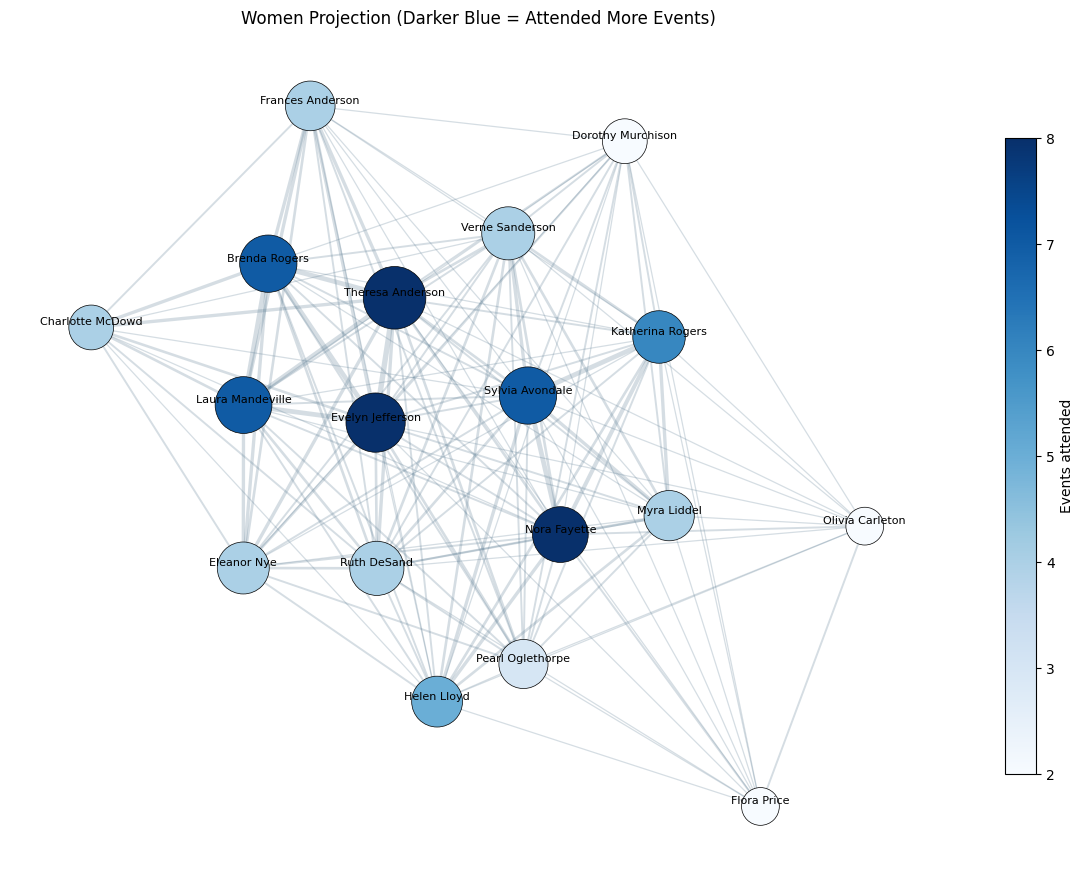

In [11]:
fig, ax = plt.subplots(figsize=(12, 9))
pos_w = nx.spring_layout(women_graph, seed=620, weight="weight")
weights_w = [women_graph[u][v]["weight"] for u, v in women_graph.edges()]
node_values_w = [G.degree(w) for w in women_graph.nodes()]
node_sizes_w = [320 + 30 * women_graph.degree(w, weight="weight") for w in women_graph.nodes()]

nx.draw_networkx_edges(
    women_graph, pos_w,
    width=[0.4 + 0.5 * x for x in weights_w],
    alpha=0.25, edge_color="#597a91", ax=ax
)
nodes = nx.draw_networkx_nodes(
    women_graph, pos_w,
    node_size=node_sizes_w,
    node_color=node_values_w,
    cmap=plt.cm.Blues,
    edgecolors="black", linewidths=0.5,
    ax=ax
)
nx.draw_networkx_labels(women_graph, pos_w, font_size=8, font_color="black", verticalalignment="bottom", ax=ax)

cbar = fig.colorbar(nodes, ax=ax, shrink=0.75)
cbar.set_label("Events attended")
ax.set_title("Women Projection (Darker Blue = Attended More Events)")
ax.axis("off")
fig.tight_layout()
plt.show()

## 8. Connections between events

Here I linked events if they had at least one woman attending both. The weight is the number of women they had in common.

In [12]:
# Create event-to-event links from shared attendees; weight counts the shared women.
events_graph = bipartite.weighted_projected_graph(G, events)
print("Events in projection:", events_graph.number_of_nodes())
print("Event pairs with shared attendees:", events_graph.number_of_edges())

event_pairs = sorted(
    [(a, b, d["weight"]) for a, b, d in events_graph.edges(data=True)],
    key=lambda x: (-x[2], x[0], x[1])
)
pd.DataFrame(event_pairs[:12], columns=["event_1", "event_2", "shared_women"])

Events in projection: 14
Event pairs with shared attendees: 66


,event_1,event_2,shared_women
0,E8,E9,9
1,E7,E8,8
2,E5,E8,7
3,E6,E8,7
4,E3,E5,6
5,E5,E6,6
6,E5,E7,6
7,E10,E12,5
8,E3,E6,5
9,E3,E8,5


### Events with shared attendees

Darker orange means more women attended the event. The thicker lines show more shared attendees.

In [13]:
event_summary = pd.DataFrame({
    "event": events,
    "women_attending": [G.degree(e) for e in events],
    "other_events": [events_graph.degree(e) for e in events],
    "shared_attendee_total": [events_graph.degree(e, weight="weight") for e in events]
}).sort_values(["shared_attendee_total", "event"], ascending=[False, True])
event_summary

,event,women_attending,other_events,shared_attendee_total
7,E8,14,13,59
6,E7,10,13,48
8,E9,12,13,46
5,E6,8,13,41
4,E5,8,8,38
2,E3,6,8,32
11,E12,6,8,28
9,E10,5,8,25
3,E4,4,8,23
1,E2,3,8,20


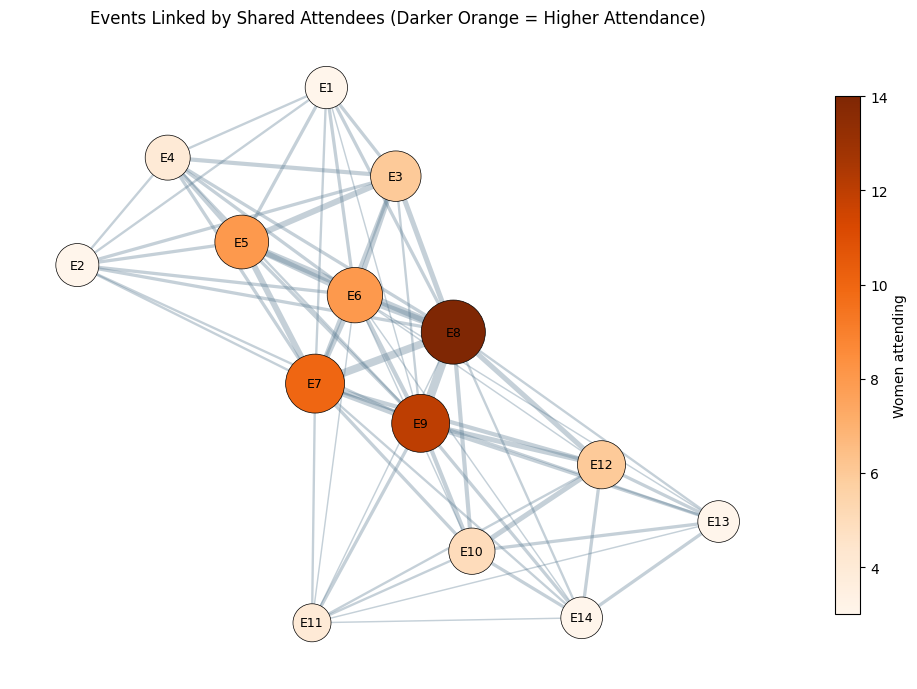

In [14]:
fig, ax = plt.subplots(figsize=(10, 7))
pos_e = nx.spring_layout(events_graph, seed=620, weight="weight")
weights_e = [events_graph[u][v]["weight"] for u, v in events_graph.edges()]
node_values_e = [G.degree(e) for e in events_graph.nodes()]
node_sizes_e = [360 + 30 * events_graph.degree(e, weight="weight") for e in events_graph.nodes()]

nx.draw_networkx_edges(
    events_graph, pos_e,
    width=[0.4 + 0.65 * x for x in weights_e],
    edge_color="#597a91", alpha=.35, ax=ax
)
nodes = nx.draw_networkx_nodes(
    events_graph, pos_e,
    node_color=node_values_e,
    cmap=plt.cm.Oranges,
    node_size=node_sizes_e,
    edgecolors="black", linewidths=0.5,
    ax=ax
)
nx.draw_networkx_labels(events_graph, pos_e, font_size=9, ax=ax)

cbar = fig.colorbar(nodes, ax=ax, shrink=0.8)
cbar.set_label("Women attending")
ax.set_title("Events Linked by Shared Attendees (Darker Orange = Higher Attendance)")
ax.axis("off")
fig.tight_layout()
plt.show()

## 9. What I found

### The women

Theresa Anderson and Evelyn Jefferson each attended eight events. They went to seven of the same events, which is the highest overlap between two women in this dataset.

There were 139 pairs of women who shared at least one event. Theresa had the highest total shared-event count, at 57 across her connections. That suggests she had a lot of opportunities to meet other women at these events. I cannot tell from attendance alone if they actually knew each other well.

### The events

E8 had the most women attending, with 14. E9 had 12, and E7 had 10. E8 and E9 also shared nine attendees, more than any other pair of events.

There were 66 pairs of events with at least one attendee in common. E8 stood out because it had the highest attendance and the most overlap with the other events.

### One limitation

The projected graphs make the overlaps easier to compare, but there is a tradeoff. A popular event can connect many women even when they attended only that one event together. I also cannot tell whether the women spoke or were friends. So the findings are about shared attendance, not proven friendships.

## References

Davis, A., Gardner, B. B., & Gardner, M. R. (1941). *Deep South: A Social Anthropological Study of Caste and Class*. University of Chicago Press.

NetworkX Developers. (2026). *Davis Club* [Code example]. https://networkx.org/documentation/stable/auto_examples/algorithms/plot_davis_club.html

NetworkX Developers. (2026). *davis_southern_women_graph* [Documentation]. https://networkx.org/documentation/stable/reference/generated/networkx.generators.social.davis_southern_women_graph.html

University of Ljubljana network data collection. *UCINET datasets: Davis Southern Women*. http://vlado.fmf.uni-lj.si/pub/networks/data/ucinet/ucidata.htm#davis

**AI use:** ChatGPT assisted with code review and editing.